# Titanic - Machine Learning from Disaster
**Author:** Matthew Ilori 

###  The Challenge
The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone onboard, resulting in the death of 1502 out of 2224 passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

pd.set_option('display.float_format', lambda x: '{:.2f}'.format(x))
np.set_printoptions(suppress=True)

## 2. Data Loading

In [2]:
df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.shape, df_test.shape

((891, 12), (418, 11))

In [3]:
df_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


In [4]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [5]:
df_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.50,0,0,330911,7.83,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.00,1,0,363272,7.00,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.00,0,0,240276,9.69,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.00,0,0,315154,8.66,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.00,1,1,3101298,12.29,NaN,S


In [6]:
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


From loading the data, it can be observed that the target column is missing from the df_test. All data exploration will be done on the training data, while the feature engineering and data cleaning will be carried on the training data then moved to the test data

## 3. Data Quality Checks

### 3.1 Target Variable

Checking to see the distribution of classes in the target variable 

In [7]:
df_train['Survived'].value_counts(normalize=True)

Survived
0   0.62
1   0.38
Name: proportion, dtype: float64

On the train data, 38% of the people on the ship survived. The data doesn't seem too imbalanced.

### 3.2 Changing the Case of the columns to lowercases

In [8]:
# For the Train data
df_train.columns = df_train.columns.str.lower()
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   name         891 non-null    str    
 4   sex          891 non-null    str    
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    str    
 9   fare         891 non-null    float64
 10  cabin        204 non-null    str    
 11  embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [9]:
# For the Test data
df_test.columns = df_test.columns.str.lower()
df_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  418 non-null    int64  
 1   pclass       418 non-null    int64  
 2   name         418 non-null    str    
 3   sex          418 non-null    str    
 4   age          332 non-null    float64
 5   sibsp        418 non-null    int64  
 6   parch        418 non-null    int64  
 7   ticket       418 non-null    str    
 8   fare         417 non-null    float64
 9   cabin        91 non-null     str    
 10  embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


### 3.3 Checking for Duplicate data

In [10]:
# Train data
df_train.duplicated().sum()

np.int64(0)

In [11]:
# Test data
df_test.duplicated().sum()

np.int64(0)

No duplicates found in the data

### 3.4 Checking for Null values

In [12]:
df_train.isna().sum()

passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

For age, which is a numerical column, there are about 177 null values, with just 2 null values in the embarked column while the cabin column has about 77% of its rows null

In [13]:
df_test.isna().sum()

passengerid      0
pclass           0
name             0
sex              0
age             86
sibsp            0
parch            0
ticket           0
fare             1
cabin          327
embarked         0
dtype: int64

Proposed solution: 

| Column     | Missing | Share | Suggested treatment                                                    |
| ---------- | ------: | ----: | ---------------------------------------------------------------------- |
| `embarked` |       2 |  0.2% | Fill with the most common port                                         |
| `age`      |     177 |   20% | Add a “was missing” flag, then fill with the median age for each title |
| `cabin`    |     687 |   77% | Don’t fill. Turn it into a “has cabin” feature, then drop the original |


#### Missing Data: Embarked Column

In [14]:
# Treating Embarked column

df_train['embarked'].value_counts()

embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [15]:
mode_value = df_train['embarked'].mode()[0]

df_train['embarked'] = df_train['embarked'].fillna(mode_value)

df_train['embarked'].value_counts()

embarked
S    646
C    168
Q     77
Name: count, dtype: int64

In [16]:
df_train['embarked'].isna().sum()

np.int64(0)

#### Missing Data: Age Column

In [17]:
# Adding a column that records whether age was missing to compare the survival rate of passengers with and without a recorded age

df_train['has_age'] = df_train['age'].notna().astype(int)
df_train['has_age'].value_counts()

has_age
1    714
0    177
Name: count, dtype: int64

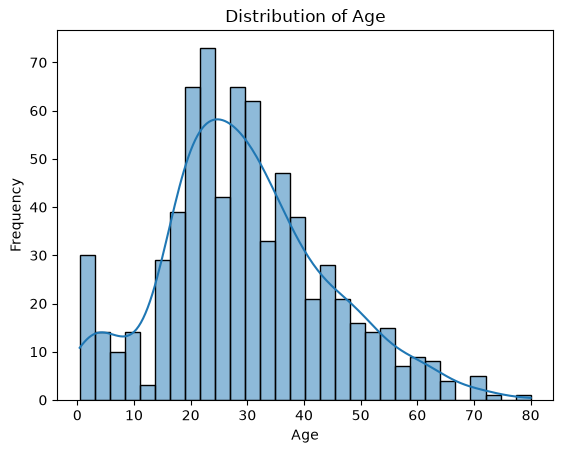

In [18]:
#Distribution of Age before Cleaning
sns.histplot(data=df_train, x='age', bins=30, kde=True)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [19]:
# Comparing survival rate for passengers with an age vs. missing age

survival_by_age = (
    df_train.groupby('has_age')['survived']
    .mean()
    .mul(100)
)

print(survival_by_age)

has_age
0   29.38
1   40.62
Name: survived, dtype: float64


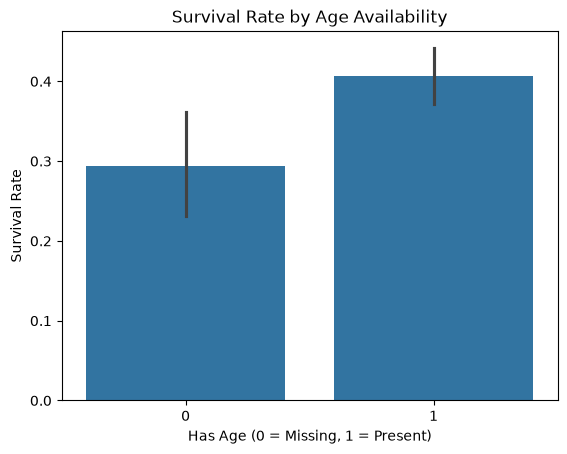

In [20]:
sns.barplot(data=df_train, x='has_age', y='survived')

plt.title('Survival Rate by Age Availability')
plt.xlabel('Has Age (0 = Missing, 1 = Present)')
plt.ylabel('Survival Rate')
plt.show()

People with ages recorded have a better survival rate than people without ages recorded

Extract titles from the names and group the rare ones.

In [21]:
# Creating a title column

df_train['title'] = df_train['name'].str.extract(r',\s*([^.]*)\.') #Extracting the title

title_counts = df_train['title'].value_counts()

df_train['title'] = df_train['title'].where(
    df_train['title'].isin(title_counts[title_counts >= 10].index),
    'Rare'
)

df_train['title'].value_counts()

title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

Group the age by titles and use the median of that result to fill the missing ages

In [22]:
df_train['age'] = df_train['age'].fillna(
    df_train.groupby('title')['age'].transform('median')
)

df_train['age'].isna().sum()

np.int64(0)

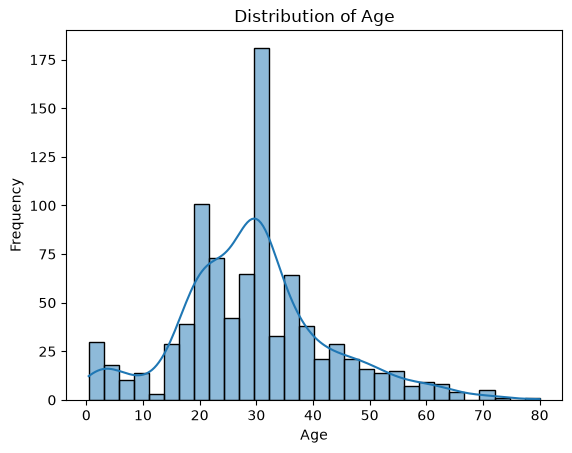

In [23]:
#Distribution of Age before Cleaning
sns.histplot(data=df_train, x='age', bins=30, kde=True)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

The shape of the histogram stays more or less the same with the frequency of the age increasing for ages between 20 and 40

In [24]:
# Doing the same for the test data.

df_test['has_age'] = df_test['age'].notna().astype(int)
df_test['has_age'].value_counts()

has_age
1    332
0     86
Name: count, dtype: int64

In [25]:
df_test['title'] = df_test['name'].str.extract(r',\s*([^.]*)\.') #Extracting the title

title_counts = df_test['title'].value_counts()

df_test['title'] = df_test['title'].where(
    df_test['title'].isin(title_counts[title_counts >= 10].index),
    'Rare'
)

df_test['title'].value_counts()

title
Mr        240
Miss       78
Mrs        72
Master     21
Rare        7
Name: count, dtype: int64

In [26]:
df_test['age'] = df_test['age'].fillna(
    df_test.groupby('title')['age'].transform('median')
)

df_test['age'].isna().sum()

np.int64(0)

In [27]:
df_train['age'].isna().sum()

np.int64(0)

In [28]:
df_train.shape, df_test.shape

((891, 14), (418, 13))

#### Missing Data: Cabin

In [29]:
# Creating a new column named 'has_cabin'  from the cabin column.
df_train['has_cabin'] = df_train['cabin'].notna().astype(int)
df_test['has_cabin'] = df_test['cabin'].notna().astype(int)
df_train['has_cabin'].value_counts()

has_cabin
0    687
1    204
Name: count, dtype: int64

In [30]:
# Create a new column named 'deck' from the cabin column

# Extract the first letter of the cabin
df_train['deck'] = df_train['cabin'].str[0]

# Count deck frequencies
deck_counts = df_train['deck'].value_counts()

# Replace missing and decks with fewer than 10 occurrences with 'Unknown'
df_train['deck'] = df_train['deck'].where(
    df_train['deck'].map(deck_counts).ge(10),
    'Unknown'
)

# Check the result
df_train['deck'].value_counts()

deck
Unknown    692
C           59
B           47
D           33
E           32
A           15
F           13
Name: count, dtype: int64

In [31]:
# Relationship between the Passenger Classes and Decks
pd.crosstab(
    df_train['pclass'],
    df_train['deck'],
    normalize='index'
).mul(100).round(1)

deck,A,B,C,D,E,F,Unknown
pclass,,,,,,,
1,6.90,21.80,27.30,13.40,11.60,0.00,19.00
2,0.00,0.00,0.00,2.20,2.20,4.30,91.30
3,0.00,0.00,0.00,0.00,0.60,1.00,98.40


In [32]:
df_train.groupby(['pclass', 'deck'])['survived'].mean().mul(100).round(1)

pclass  deck   
1       A          46.70
        B          74.50
        C          59.30
        D          75.90
        E          72.00
        Unknown    46.30
2       D          75.00
        E          75.00
        F          87.50
        Unknown    44.00
3       E         100.00
        F          20.00
        Unknown    23.80
Name: survived, dtype: float64

In [33]:
df_train.groupby(['pclass', 'deck'])['survived'].agg(
    ['count', 'mean']
).assign(
    survival_rate=lambda x: x['mean'] * 100
).round(2)

count  mean  survival_rate
pclass deck                               
1      A           15  0.47          46.67
       B           47  0.74          74.47
       C           59  0.59          59.32
       D           29  0.76          75.86
       E           25  0.72          72.00
       Unknown     41  0.46          46.34
2      D            4  0.75          75.00
       E            4  0.75          75.00
       F            8  0.88          87.50
       Unknown    168  0.44          44.05
3      E            3  1.00         100.00
       F            5  0.20          20.00
       Unknown    483  0.24          23.81

#### Deck and Passenger Class Analysis

The `cabin` column contains a large proportion of missing values, so the first letter of the cabin number was extracted to create a `deck` feature. Decks with fewer than 10 observations, as well as missing cabin values, were grouped into `Unknown`.

### Relationship Between Pclass and Deck

A cross-tabulation of `pclass` and `deck` shows a strong relationship between passenger class and deck:

| Pclass | A | B | C | D | E | F | Unknown |
|---|---:|---:|---:|---:|---:|---:|---:|
| **1st** | 6.9% | 21.8% | 27.3% | 13.4% | 11.6% | 0.0% | 19.0% |
| **2nd** | 0.0% | 0.0% | 0.0% | 2.2% | 2.2% | 4.3% | 91.3% |
| **3rd** | 0.0% | 0.0% | 0.0% | 0.0% | 0.6% | 1.0% | 98.4% |

Most passengers with known deck information are in **1st class**, while cabin information is missing for the vast majority of 2nd- and 3rd-class passengers.

- 19.0% of 1st-class passengers have an `Unknown` deck.
- 91.3% of 2nd-class passengers have an `Unknown` deck.
- 98.4% of 3rd-class passengers have an `Unknown` deck.

This suggests that `deck` and `pclass` are strongly associated.

### Survival Rate by Pclass and Deck

Survival rates were then examined within each `pclass` and `deck` combination:

| Pclass | Deck | Count | Survival Rate |
|---|---|---:|---:|
| 1st | A | 15 | 46.67% |
| 1st | B | 47 | 74.47% |
| 1st | C | 59 | 59.32% |
| 1st | D | 29 | 75.86% |
| 1st | E | 25 | 72.00% |
| 1st | Unknown | 41 | 46.34% |
| 2nd | D | 4 | 75.00% |
| 2nd | E | 4 | 75.00% |
| 2nd | F | 8 | 87.50% |
| 2nd | Unknown | 168 | 44.05% |
| 3rd | E | 3 | 100.00% |
| 3rd | F | 5 | 20.00% |
| 3rd | Unknown | 483 | 23.81% |

The results suggest that `deck` may provide additional information about survival beyond `pclass`. However, some deck/class combinations have very small sample sizes, so their survival rates should be interpreted cautiously.

For example, the **100% survival rate for 3rd-class passengers on deck E is based on only 3 passengers**, while the 23.81% rate for 3rd-class passengers with an unknown deck is based on 483 passengers and is therefore much more informative.

### Feature Engineering Decision

Based on the analysis, `deck` will be retained as a feature rather than dropping the cabin information entirely. The `Unknown` category is also retained because missing cabin information appears to be associated with passenger class and survival.

The original `cabin` column can subsequently be dropped after extracting the useful information into `deck`.

Potential features:

- `pclass` — passenger class
- `deck` — extracted cabin deck
- `has_cabin` — whether the original cabin information was available

In [34]:
# Create a new column named 'deck' from the cabin column for test

# Extract the first letter of the cabin
df_test['deck'] = df_test['cabin'].str[0]

# Count deck frequencies
deck_counts = df_test['deck'].value_counts()

# Replace missing and decks with fewer than 10 occurrences with 'Unknown'
df_test['deck'] = df_test['deck'].where(
    df_test['deck'].map(deck_counts).ge(10),
    'Unknown'
)

# Check the result
df_test['deck'].value_counts()

deck
Unknown    352
C           35
B           18
D           13
Name: count, dtype: int64

In [35]:
# Comparing survival rate for passengers with cabin vs. missing cabin

survival_by_cabin = (
    df_train.groupby('has_cabin')['survived']
    .mean()
    .mul(100)
)

print(survival_by_cabin)

has_cabin
0   29.99
1   66.67
Name: survived, dtype: float64


In [36]:
# Dropping the Cabin column

df_train = df_train.drop(columns = 'cabin')
df_test = df_test.drop(columns = 'cabin')

#### Missing Data: Fare

In [37]:
median_value = df_test['fare'].median()
median_value

np.float64(14.4542)

In [38]:
df_test['fare'] = df_test['fare'].fillna(median_value)

### 3.5 Handling missing values: decisions and reasons

The training data has 891 rows and the test data has 418. Four columns have missing values across the two datasets:

| Column | Missing (train) | Share (train) | Missing (test) | Decision |
|---|---|---|---|---|
| `age` | 177 | 19.9% | 86 | Flag as missing, then fill with the median age for the passenger's title |
| `cabin` | 687 | 77.1% | 327 | Convert to `has_cabin` and `deck` features, then drop |
| `embarked` | 2 | 0.2% | 0 | Fill with the most common port |
| `fare` | 0 | 0% | 1 | Fill with the median fare for the passenger's class |

**Rules applied to every column**
- **No rows are dropped.** Kaggle needs a prediction for all 418 test passengers, and dropping the 177 training rows with no age would throw away a fifth of the training data.
- **Fill values come from the training data only.** Every median and mode is calculated on the training data and then applied unchanged to the test data. Calculating them from the test data would leak information about it into the model.
- **Missing values can be information.** Where the gaps might relate to survival, a flag is kept so the model can learn from them.

**`embarked`: fill with the most common port**
- Only 2 of 891 rows are missing, so the choice has almost no effect on the model and a simple fill is enough.
- Most common port in the training data: 64
- The two rows were inspected before filling: S

**`age`: add a missing-value flag, then fill with the median by title**
- Age can't be dropped. It directly affected who got into the lifeboats ("women and children first"), and 20% of rows is too many to lose.
- A single overall median would give all 177 passengers the same age. That creates an artificial spike in the distribution and treats missing children as adults.
- Each passenger's title is taken from `name` (Mr, Mrs, Miss, Master). Titles carry age information: "Master" was used for young boys, so filling by title gives children a child's age.
- Rare titles (Dr, Rev, Col, Countess and similar) are grouped as "Rare", and French forms become their English equivalents (Mlle to Miss, Mme to Mrs). This gives each group enough passengers for a reliable median.
- The median is used rather than the mean because a few very old passengers pull the mean up, but barely move the median.
- Before filling, a new column `age_missing` records which ages were missing. Survival rate with a recorded age: 40%. Without: 30%.


**`cabin`: convert to features, then drop**
- 77% missing is too much to fill. Any cabin number put in would be made up.
- The gaps are not random: cabins were mostly recorded for first-class passengers. So the column is turned into features instead of being thrown away:
  - `has_cabin`: 1 if a cabin is recorded, 0 if not. Survival rate with a cabin: 67%. Without: 30%.
  - `deck`: the first letter of the cabin, with missing values grouped as "U" (Unknown). The deck roughly shows how high up the ship a passenger was, and so how close to the lifeboats.
- `has_cabin` overlaps with `pclass`. Share of recorded cabins belonging to first-class passengers: 71%. If this is very high, `has_cabin` may add little beyond `pclass`. This will be checked during modelling.
- The original `cabin` column is then dropped.

**`fare` (test data only): median fare for the passenger's class**
- One test passenger has no fare. The training data has no missing fares, so this gap only shows up at prediction time.
- Fare depends heavily on class, so the median fare for that passenger's class (from the training data) is a closer estimate than the overall median.

**Check after treatment**
- Null counts on both datasets after all steps: 0 (expected: zero in every column)

## 4. Explore relationships with survival (next)


#### 4.1 Step 1: What share of passengers survived?

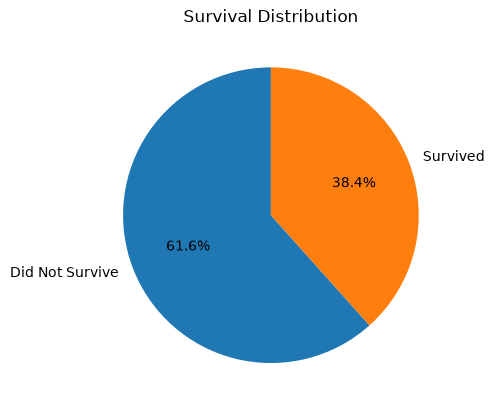

In [39]:
survival_pct = df_train['survived'].value_counts(normalize=True)

plt.pie(
    survival_pct,
    labels=['Did Not Survive', 'Survived'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Survival Distribution')
plt.show()

In [40]:
survival_pct

survived
0   0.62
1   0.38
Name: proportion, dtype: float64

#### 4.2 Univariate Analysis

##### Categorical Columns

In [41]:
category_columns = df_train.select_dtypes('str').columns.to_list()
category_columns

['name', 'sex', 'ticket', 'embarked', 'title', 'deck']

In [42]:
category_cols = ['sex', 'embarked', 'title', 'deck']

In [43]:
for col in category_cols:
    summary = (
        df_train.groupby(col)['survived']
        .agg(
            survival_rate='mean',
            passenger_count='count'
        )
        .sort_values('survival_rate', ascending=False)
    )
    
    summary['survival_rate'] = summary['survival_rate'] * 100
    
    print(f'\n--- {col.upper()} ---')
    display(summary)


--- SEX ---


,survival_rate,passenger_count
sex,,
female,74.20,314
male,18.89,577



--- EMBARKED ---


,survival_rate,passenger_count
embarked,,
C,55.36,168
Q,38.96,77
S,33.90,646



--- TITLE ---


,survival_rate,passenger_count
title,,
Mrs,79.20,125
Miss,69.78,182
Master,57.50,40
Rare,44.44,27
Mr,15.67,517



--- DECK ---


,survival_rate,passenger_count
deck,,
D,75.76,33
E,75.00,32
B,74.47,47
F,61.54,13
C,59.32,59
A,46.67,15
Unknown,30.06,692


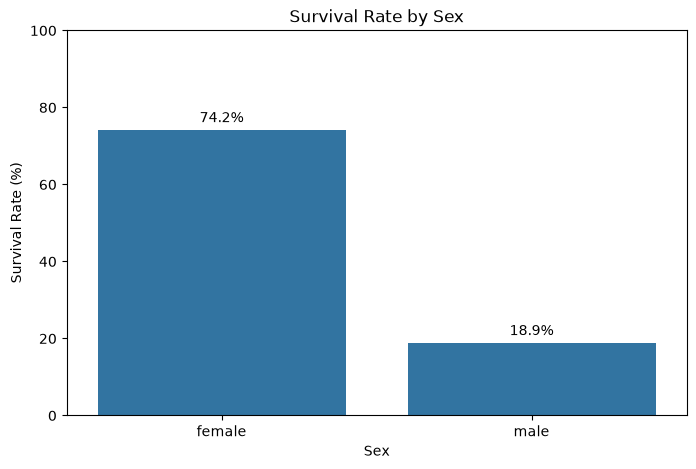

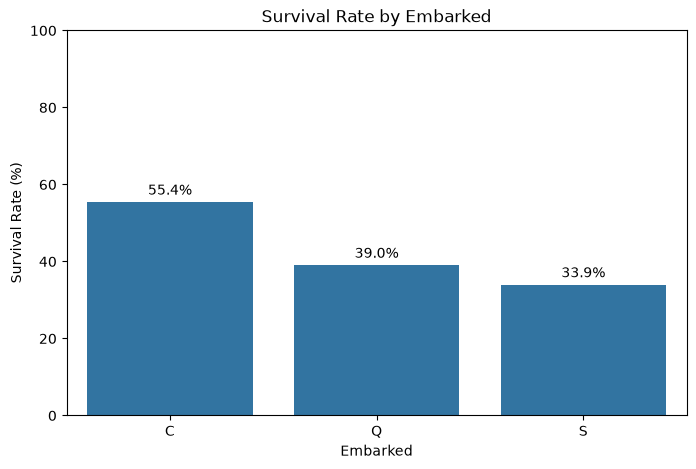

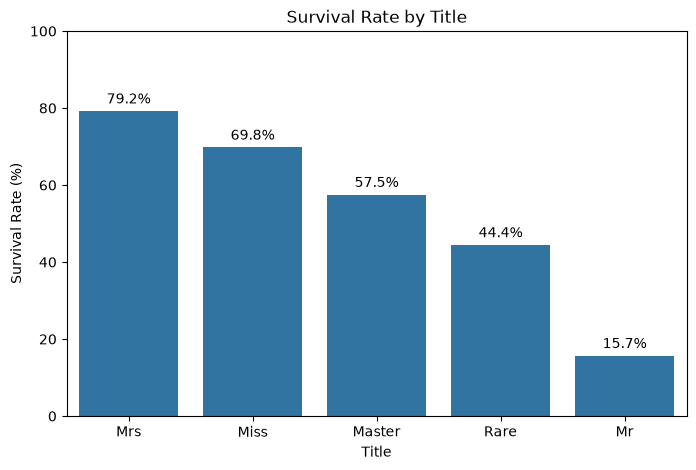

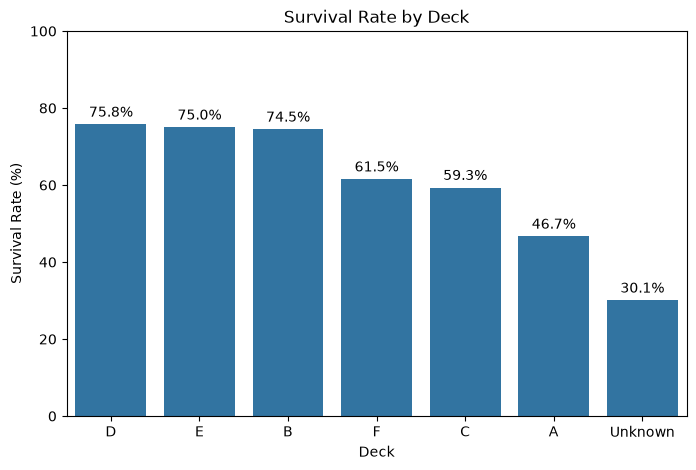

In [44]:
for col in category_cols:
    summary = (
        df_train.groupby(col)['survived']
        .mean()
        .sort_values(ascending=False)
        * 100
    )

    plt.figure(figsize=(8, 5))
    sns.barplot(
        x=summary.index,
        y=summary.values
    )

    plt.title(f'Survival Rate by {col.title()}')
    plt.xlabel(col.title())
    plt.ylabel('Survival Rate (%)')
    plt.ylim(0, 100)

    # Add percentage labels
    for i, value in enumerate(summary.values):
        plt.text(
            i,
            value + 2,
            f'{value:.1f}%',
            ha='center'
        )
plt.show()

##### Numerical Columns

In [45]:
numerical_columns = df_train.select_dtypes(['int64', 'float64']).columns.to_list()

numerical_columns

['passengerid',
 'survived',
 'pclass',
 'age',
 'sibsp',
 'parch',
 'fare',
 'has_age',
 'has_cabin']

In [46]:
continuous_cols = [ 'age','fare']

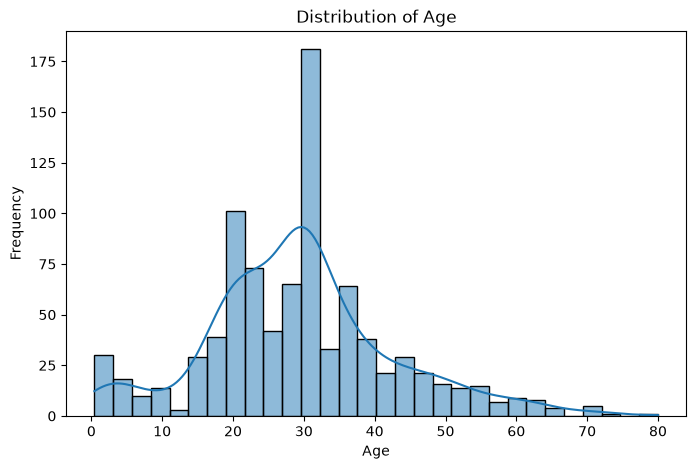

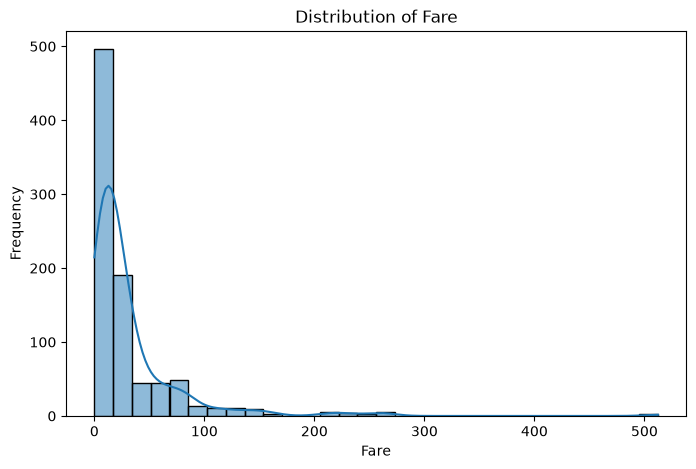

In [47]:
for col in continuous_cols:
    plt.figure(figsize=(8, 5))
    
    sns.histplot(
        data=df_train,
        x=col,
        bins=30,
        kde=True
    )
    
    plt.title(f'Distribution of {col.title()}')
    plt.xlabel(col.title())
    plt.ylabel('Frequency')
    plt.show()

The fare is rightly skewed. Shows that most people paid less than $100 to board the ship. This could well affect the deck they could have been placed on

**More Analysis into Age**

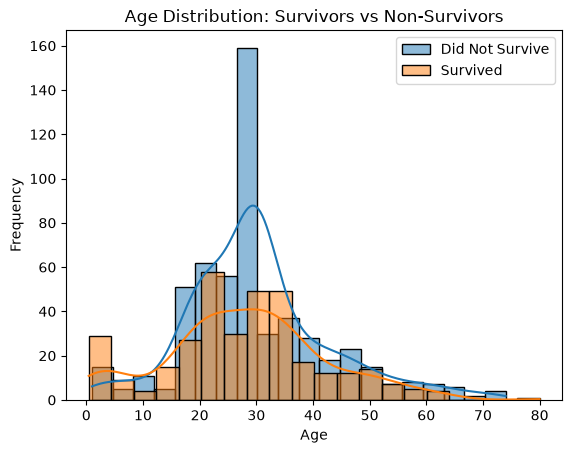

In [48]:
sns.histplot(
    data=df_train[df_train['survived'] == 0],
    x='age',
    bins=20,
    kde=True,
    alpha=0.5,
    label='Did Not Survive'
)

sns.histplot(
    data=df_train[df_train['survived'] == 1],
    x='age',
    bins=20,
    kde=True,
    alpha=0.5,
    label='Survived'
)

plt.title('Age Distribution: Survivors vs Non-Survivors')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.legend()
plt.show()

Children seemed to survive more but that changed from ages 10 and above

### 4.3 Features in Combination

In [49]:
# Sex and class together.
sex_class = (
    df_train.groupby(['sex', 'pclass'])['survived']
    .agg(
        survival_rate='mean',
        passenger_count='size'
    )
)

sex_class['survival_rate'] *= 100

sex_class

survival_rate  passenger_count
sex    pclass                                
female 1               96.81               94
       2               92.11               76
       3               50.00              144
male   1               36.89              122
       2               15.74              108
       3               13.54              347

From the table above, there seems like women are more likely to survive than men overall

In [50]:
# Age within sex
age_sex = (
    df_train.groupby(['sex', 'title'])['survived']
    .agg(
        survival_rate='mean',
        passenger_count='size'
    )
)

age_sex['survival_rate'] *= 100

age_sex

survival_rate  passenger_count
sex    title                                 
female Miss            69.78              182
       Mrs             79.20              125
       Rare           100.00                7
male   Master          57.50               40
       Mr              15.67              517
       Rare            25.00               20

In [51]:
# Port and class

port_class = (
    df_train.groupby(['embarked', 'pclass'])['survived']
    .agg(
        survival_rate='mean',
        passenger_count='size'
    )
)

port_class['survival_rate'] *= 100

port_class

survival_rate  passenger_count
embarked pclass                                
C        1               69.41               85
         2               52.94               17
         3               37.88               66
Q        1               50.00                2
         2               66.67                3
         3               37.50               72
S        1               58.91              129
         2               46.34              164
         3               18.98              353

### 4.4 Step 4: Check how the features relate to each other

In [52]:
corr = df_train.corr(numeric_only=True)

corr

,passengerid,survived,pclass,age,sibsp,parch,fare,has_age,has_cabin
passengerid,1.00,-0.01,-0.04,0.04,-0.06,-0.00,0.01,0.02,0.02
survived,-0.01,1.00,-0.34,-0.08,-0.04,0.08,0.26,0.09,0.32
pclass,-0.04,-0.34,1.00,-0.35,0.08,0.02,-0.55,-0.17,-0.73
age,0.04,-0.08,-0.35,1.00,-0.27,-0.19,0.10,0.05,0.24
sibsp,-0.06,-0.04,0.08,-0.27,1.00,0.41,0.16,-0.02,-0.04
parch,-0.00,0.08,0.02,-0.19,0.41,1.00,0.22,0.12,0.04
fare,0.01,0.26,-0.55,0.10,0.16,0.22,1.00,0.10,0.48
has_age,0.02,0.09,-0.17,0.05,-0.02,0.12,0.10,1.00,0.14
has_cabin,0.02,0.32,-0.73,0.24,-0.04,0.04,0.48,0.14,1.00


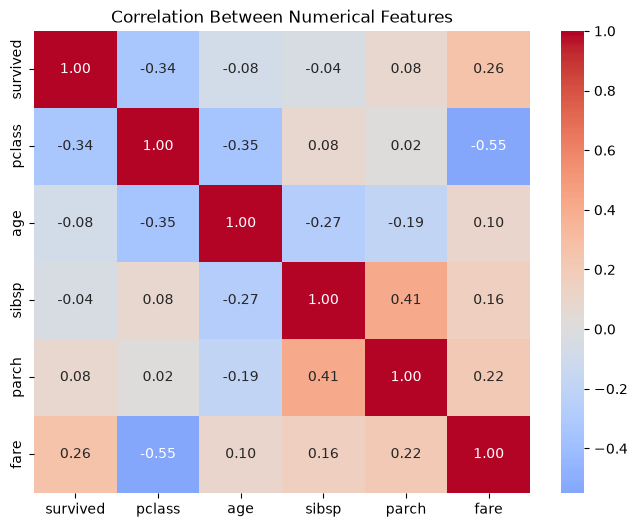

In [53]:
num_cols = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

corr = df_train[num_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0
)

plt.title('Correlation Between Numerical Features')
plt.show()

### Summary Findings

1) There is some correlation between some features in the dataset and the target like pclass (-0.34) and fare(0.26)
2) There's a strong correlation between pclass and fare (-0.55) which is a bit weird, was expecting a positive correlation
3) Children seemed to survive more but that changed from ages 10 and above
4) Females had a much higher survival rate that Males generally with Adult males having the least chances of survival (There were more Male passengers)
5) About 62% of the passengers in the train dataset did not survive the shipwreck.
6) hare of recorded cabins belonging to first-class passengers: 71%. If this is very high, has_cabin may add little beyond pclass. This will be checked during modelling.

### Feature Engineering

#### Creating a Family Size Column

In [54]:
# Add sibsp and parch, plus one for the passenger themselves.

df_train['family_size'] = df_train['sibsp']+ df_train['parch'] + 1
df_test['family_size'] = df_test['sibsp']+ df_test['parch'] + 1

df_train.describe()

,passengerid,survived,pclass,age,sibsp,parch,fare,has_age,has_cabin,family_size
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.39,0.52,0.38,32.20,0.80,0.23,1.90
std,257.35,0.49,0.84,13.26,1.10,0.81,49.69,0.40,0.42,1.61
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00,0.00,0.00,1.00
25%,223.50,0.00,2.00,21.00,0.00,0.00,7.91,1.00,0.00,1.00
50%,446.00,0.00,3.00,30.00,0.00,0.00,14.45,1.00,0.00,1.00
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00,1.00,0.00,2.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33,1.00,1.00,11.00


#### Travelling alone. A yes/no flag for a family size of 1.

In [55]:
df_train['travelling_alone'] = (df_train['family_size'] == 1).astype(int)
df_test['travelling_alone'] = (df_test['family_size'] == 1).astype(int)

df_train.describe()

,passengerid,survived,pclass,age,sibsp,parch,fare,has_age,has_cabin,family_size,travelling_alone
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.39,0.52,0.38,32.20,0.80,0.23,1.90,0.60
std,257.35,0.49,0.84,13.26,1.10,0.81,49.69,0.40,0.42,1.61,0.49
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00,0.00,0.00,1.00,0.00
25%,223.50,0.00,2.00,21.00,0.00,0.00,7.91,1.00,0.00,1.00,0.00
50%,446.00,0.00,3.00,30.00,0.00,0.00,14.45,1.00,0.00,1.00,1.00
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00,1.00,0.00,2.00,1.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33,1.00,1.00,11.00,1.00


#### Fare per person: 

Some groups shared a ticket, and the fare shown covers the whole group. Count how many passengers share each ticket number and divide the fare by that count.

In [56]:
# Count how many passengers share each ticket
ticket_counts = df_train['ticket'].value_counts()

# Map the count back to each passenger
df_train['ticket_group_size'] = df_train['ticket'].map(ticket_counts)

# Calculate fare per person
df_train['fare_per_person'] = (
    df_train['fare'] / df_train['ticket_group_size']
)

df_train.describe()

,passengerid,survived,pclass,age,sibsp,parch,fare,has_age,has_cabin,family_size,travelling_alone,ticket_group_size,fare_per_person
count,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.39,0.52,0.38,32.20,0.80,0.23,1.90,0.60,1.79,17.79
std,257.35,0.49,0.84,13.26,1.10,0.81,49.69,0.40,0.42,1.61,0.49,1.36,21.22
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00
25%,223.50,0.00,2.00,21.00,0.00,0.00,7.91,1.00,0.00,1.00,0.00,1.00,7.76
50%,446.00,0.00,3.00,30.00,0.00,0.00,14.45,1.00,0.00,1.00,1.00,1.00,8.85
75%,668.50,1.00,3.00,35.00,1.00,0.00,31.00,1.00,0.00,2.00,1.00,2.00,24.29
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33,1.00,1.00,11.00,1.00,7.00,221.78


In [57]:
# Count how many passengers share each ticket
ticket_counts = df_test['ticket'].value_counts()

# Map the count back to each passenger
df_test['ticket_group_size'] = df_test['ticket'].map(ticket_counts)

# Calculate fare per person
df_test['fare_per_person'] = (
    df_test['fare'] / df_test['ticket_group_size']
)

df_test.describe()

,passengerid,pclass,age,sibsp,parch,fare,has_age,has_cabin,family_size,travelling_alone,ticket_group_size,fare_per_person
count,418.00,418.00,418.00,418.00,418.00,418.00,418.00,418.00,418.00,418.00,418.00,418.00
mean,1100.50,2.27,29.71,0.45,0.39,35.58,0.79,0.22,1.84,0.61,1.35,24.15
std,120.81,0.84,12.99,0.90,0.98,55.85,0.40,0.41,1.52,0.49,0.76,36.89
min,892.00,1.00,0.17,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00,0.00
25%,996.25,1.00,22.00,0.00,0.00,7.90,1.00,0.00,1.00,0.00,1.00,7.85
50%,1100.50,3.00,28.50,0.00,0.00,14.45,1.00,0.00,1.00,1.00,1.00,12.54
75%,1204.75,3.00,36.50,1.00,0.00,31.47,1.00,0.00,2.00,1.00,1.00,26.55
max,1309.00,3.00,76.00,8.00,9.00,512.33,1.00,1.00,11.00,1.00,5.00,512.33


#### Handling the fare skew

Because a few fares are huge, consider a log transform or grouping fares into bands. This mostly matters for logistic regression.

In [58]:
df_train['log_fare'] = np.log1p(df_train['fare'])
df_test['log_fare'] = np.log1p(df_test['fare'])

df_train['log_fare'].describe()

count   891.00
mean      2.96
std       0.97
min       0.00
25%       2.19
50%       2.74
75%       3.47
max       6.24
Name: log_fare, dtype: float64

#### Decide the final column list

In [59]:
cols_to_drop = ['passengerid', 'name', 'ticket', 'parch', 'sibsp', 'fare']

df_train_1 = df_train.drop(columns=cols_to_drop)
df_test_1 = df_test.drop(columns=cols_to_drop)

df_train_1.columns, df_test_1.columns

(Index(['survived', 'pclass', 'sex', 'age', 'embarked', 'has_age', 'title',
        'has_cabin', 'deck', 'family_size', 'travelling_alone',
        'ticket_group_size', 'fare_per_person', 'log_fare'],
       dtype='str'),
 Index(['pclass', 'sex', 'age', 'embarked', 'has_age', 'title', 'has_cabin',
        'deck', 'family_size', 'travelling_alone', 'ticket_group_size',
        'fare_per_person', 'log_fare'],
       dtype='str'))

In [60]:
features_to_use = ['pclass', 'sex', 'age', 'embarked', 'has_age', 'title', 'family_size', 'log_fare', 
                    'has_cabin', 'deck']



## Model Training

In [61]:
X = df_train_1[features_to_use]
y = df_train_1['survived']

X.head()

,pclass,sex,age,embarked,has_age,title,family_size,log_fare,has_cabin,deck
0,3,male,22.00,S,1,Mr,2,2.11,0,Unknown
1,1,female,38.00,C,1,Mrs,2,4.28,1,C
2,3,female,26.00,S,1,Miss,1,2.19,0,Unknown
3,1,female,35.00,S,1,Mrs,2,3.99,1,C
4,3,male,35.00,S,1,Mr,1,2.20,0,Unknown


In [62]:
numeric_features = [
    'pclass',
    'age',
    'has_age',
    'family_size',
    'log_fare',
    'has_cabin'
]

categorical_features = [
    'sex',
    'title',
    'embarked',
    'deck'
]

#### Build the preprocessing pipeline

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

#### Split the data

In [64]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

#### Logistic Regression

In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

##### Fitting the model

In [66]:
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['pclass','sex','age',...,'log_fare','has_cabin','deck']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining colum

##### Model Evaluation

In [67]:
from sklearn.metrics import accuracy_score

y_pred = logistic_model.predict(X_val)

logistic_accuracy = accuracy_score(y_val, y_pred)
logistic_accuracy

0.8379888268156425

##### Using Cross Validation

In [68]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

print('CV scores:', scores)
print('Mean accuracy:', scores.mean())

CV scores: [0.81564246 0.82022472 0.81460674 0.8258427  0.85955056]
Mean accuracy: 0.8271734354403364


#### Majority Baseline

In [69]:


majority_pred = [0] * len(y_val)

majority_accuracy = accuracy_score(y_val, majority_pred)

print(f'Majority baseline: {majority_accuracy:.3f}')

Majority baseline: 0.615


#### Gender Rule

In [70]:
gender_pred = (X_val['sex'] == 'female').astype(int)

gender_accuracy = accuracy_score(y_val, gender_pred)

print(f'Gender rule: {gender_accuracy:.3f}')

Gender rule: 0.777


### RandomForestClassifier

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

tree_preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)

In [72]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=300,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_val)

rf_accuracy = accuracy_score(y_val, rf_pred)

print(f'Random Forest: {rf_accuracy:.3f}')

Random Forest: 0.799


### XGBoost

In [73]:
from xgboost import XGBClassifier

xgb_model = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        random_state=42,
        eval_metric='logloss'
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_val)

xgb_accuracy = accuracy_score(y_val, xgb_pred)

print(f'XGBoost: {xgb_accuracy:.3f}')

XGBoost: 0.810


In [74]:
results = pd.DataFrame({
    'Model': [
        'Majority Baseline',
        'Gender Rule',
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Accuracy': [
        majority_accuracy,
        gender_accuracy,
        logistic_accuracy,
        rf_accuracy,
        xgb_accuracy
    ]
})

results.sort_values('Accuracy', ascending=False)

,Model,Accuracy
2,Logistic Regression,0.84
4,XGBoost,0.81
3,Random Forest,0.80
1,Gender Rule,0.78
0,Majority Baseline,0.61


#### Checking for Overfitting of the Models

In [75]:

results = []

# 1. Majority Baseline
majority_train_pred = [0] * len(y_train)
majority_val_pred = [0] * len(y_val)

results.append({
    'Model': 'Majority Baseline',
    'Training Accuracy': accuracy_score(y_train, majority_train_pred),
    'Validation Accuracy': accuracy_score(y_val, majority_val_pred)
})


# 2. Gender Rule
gender_train_pred = (X_train['sex'] == 'female').astype(int)
gender_val_pred = (X_val['sex'] == 'female').astype(int)

results.append({
    'Model': 'Gender Rule',
    'Training Accuracy': accuracy_score(y_train, gender_train_pred),
    'Validation Accuracy': accuracy_score(y_val, gender_val_pred)
})


# 3. Logistic Regression
logistic_model.fit(X_train, y_train)

logistic_train_pred = logistic_model.predict(X_train)
logistic_val_pred = logistic_model.predict(X_val)

results.append({
    'Model': 'Logistic Regression',
    'Training Accuracy': accuracy_score(y_train, logistic_train_pred),
    'Validation Accuracy': accuracy_score(y_val, logistic_val_pred)
})


# 4. Random Forest
rf_model.fit(X_train, y_train)

rf_train_pred = rf_model.predict(X_train)
rf_val_pred = rf_model.predict(X_val)

results.append({
    'Model': 'Random Forest',
    'Training Accuracy': accuracy_score(y_train, rf_train_pred),
    'Validation Accuracy': accuracy_score(y_val, rf_val_pred)
})


# 5. XGBoost
xgb_model.fit(X_train, y_train)

xgb_train_pred = xgb_model.predict(X_train)
xgb_val_pred = xgb_model.predict(X_val)

results.append({
    'Model': 'XGBoost',
    'Training Accuracy': accuracy_score(y_train, xgb_train_pred),
    'Validation Accuracy': accuracy_score(y_val, xgb_val_pred)
})


# Comparison table
results = pd.DataFrame(results)

results['Accuracy Gap'] = (
    results['Training Accuracy'] -
    results['Validation Accuracy']
)

results

,Model,Training Accuracy,Validation Accuracy,Accuracy Gap
0,Majority Baseline,0.62,0.61,0.00
1,Gender Rule,0.79,0.78,0.01
2,Logistic Regression,0.84,0.84,-0.00
3,Random Forest,0.99,0.80,0.19
4,XGBoost,0.93,0.81,0.12


**Insights**

1. Majority baseline — 62%
Predicting "did not survive" for everyone got about 61–62%.
This establishes your minimum benchmark.

2. Gender rule — 79%
Simply predicting that women survived and men did not got 78% validation accuracy.
The tiny 1% gap is expected because this isn't a trained model.

3. Logistic Regression — 84%
The logistic model gets 84% on both training and validation. That's a very healthy result.
The near-zero gap suggests the model is generalising well rather than memorising the training data.

4. Random Forest — 99% vs 80%
This is the clearest case of overfitting. The forest almost perfectly fits the training data but drops to 80% on validation.
The 19 percentage-point gap is substantial.

5. XGBoost — 93% vs 81%
Also shows overfitting, but less severely than the random forest. The gap is 12 percentage points.
It generalises slightly better than the random forest on this split.

**More complex ≠ better generalisation.**

#### 5-fold stratified cross-validation

In [76]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

majority_scores = cross_val_score(
    DummyClassifier(strategy='most_frequent'),
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

In [77]:
# Gender Rules

gender_scores = []

for train_idx, val_idx in cv.split(X, y):
    X_val_fold = X.iloc[val_idx]
    y_val_fold = y.iloc[val_idx]

    predictions = (X_val_fold['sex'] == 'female').astype(int)

    gender_scores.append(
        accuracy_score(y_val_fold, predictions)
    )

gender_scores = np.array(gender_scores)

In [78]:
# Logistic Regression

logistic_scores = cross_val_score(
    logistic_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

In [79]:
# Random Forest

rf_scores = cross_val_score(
    rf_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

In [80]:
# XGBoost

xgb_scores = cross_val_score(
    xgb_model,
    X,
    y,
    cv=cv,
    scoring='accuracy'
)

In [81]:
# Putting everything into a table

cv_results = pd.DataFrame({
    'Model': [
        'Majority Baseline',
        'Gender Rule',
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Fold 1': [
        majority_scores[0],
        gender_scores[0],
        logistic_scores[0],
        rf_scores[0],
        xgb_scores[0]
    ],
    'Fold 2': [
        majority_scores[1],
        gender_scores[1],
        logistic_scores[1],
        rf_scores[1],
        xgb_scores[1]
    ],
    'Fold 3': [
        majority_scores[2],
        gender_scores[2],
        logistic_scores[2],
        rf_scores[2],
        xgb_scores[2]
    ],
    'Fold 4': [
        majority_scores[3],
        gender_scores[3],
        logistic_scores[3],
        rf_scores[3],
        xgb_scores[3]
    ],
    'Fold 5': [
        majority_scores[4],
        gender_scores[4],
        logistic_scores[4],
        rf_scores[4],
        xgb_scores[4]
    ]
})

cv_results['Mean Accuracy'] = cv_results.iloc[:, 1:].mean(axis=1)
cv_results['Std Dev'] = cv_results.iloc[:, 1:6].std(axis=1)

cv_results

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean Accuracy,Std Dev
0,Majority Baseline,0.61,0.62,0.62,0.62,0.61,0.62,0.00
1,Gender Rule,0.79,0.78,0.79,0.76,0.82,0.79,0.02
2,Logistic Regression,0.84,0.83,0.80,0.83,0.84,0.83,0.02
3,Random Forest,0.84,0.81,0.78,0.83,0.80,0.81,0.02
4,XGBoost,0.86,0.88,0.81,0.83,0.83,0.84,0.03


**Insights**

1. XGBoost has the highest mean cross-validation accuracy. Its fold scores range from 81% to 88%, so performance varies somewhat depending on the passengers in each validation fold.

 
2. Logistic Regression relatively small variation indicates fairly consistent performance.

3. Random Forest: The cross-validation results reinforce that the random forest's very high training accuracy was largely overfitting. Its average validation performance is only about 81%.

4. The Gender rule is a remarkably strong baseline. It is only about 4–5 percentage points below the learned models.

5. The Majority Baseline gives the benchmark that every useful model should substantially improve upon.

### Tuning the Leading Models, Logistic Regression, XGBoost and RandomForestClassifier

In [82]:
# Using GridSearchCV
from sklearn.model_selection import GridSearchCV


#### Tuning Logistic Regression

In [83]:
logistic_param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    estimator=logistic_model,
    param_grid=logistic_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

logistic_grid.fit(X, y)

print("Best Logistic Regression parameters:")
print(logistic_grid.best_params_)

print("Best CV accuracy:")
print(logistic_grid.best_score_)

Best Logistic Regression parameters:
{'model__C': 1}
Best CV accuracy:
0.8293892411022536


#### Tune Random Forest

In [84]:
rf_param_grid = {
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_leaf': [1, 2, 5, 10]
}

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_grid.fit(X, y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [3, 5, ...], 'model__min_samples_leaf': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int,

In [85]:
print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print("Best CV accuracy:")
print(rf_grid.best_score_)

Best Random Forest parameters:
{'model__max_depth': 7, 'model__min_samples_leaf': 1}
Best CV accuracy:
0.840606364948842


In [86]:
# Inspecting the combinations

rf_results = pd.DataFrame(rf_grid.cv_results_)

rf_results[
    [
        'param_model__max_depth',
        'param_model__min_samples_leaf',
        'mean_test_score',
        'std_test_score'
    ]
].sort_values(
    'mean_test_score',
    ascending=False
).head(10)

,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score
8,7,1,0.84,0.01
9,7,2,0.84,0.01
10,7,5,0.83,0.01
13,10,2,0.83,0.01
18,None,5,0.83,0.01
6,5,5,0.83,0.01
12,10,1,0.83,0.01
5,5,2,0.83,0.01
4,5,1,0.83,0.01
14,10,5,0.83,0.01


#### Tune XGBoost

In [87]:
xgb_param_grid = {
    'model__max_depth': [2, 3, 4, 5],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__n_estimators': [100, 200, 300]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

xgb_grid.fit(X, y)

print("Best XGBoost parameters:")
print(xgb_grid.best_params_)

print("Best CV accuracy:")
print(xgb_grid.best_score_)

Best XGBoost parameters:
{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV accuracy:
0.8451070240411775


In [88]:
xgb_results = pd.DataFrame(xgb_grid.cv_results_)

xgb_results[
    [
        'param_model__max_depth',
        'param_model__learning_rate',
        'param_model__n_estimators',
        'mean_test_score',
        'std_test_score'
    ]
].sort_values(
    'mean_test_score',
    ascending=False
).head(10)

,param_model__max_depth,param_model__learning_rate,param_model__n_estimators,mean_test_score,std_test_score
4,3,0.03,200,0.85,0.02
11,5,0.03,300,0.85,0.03
23,5,0.05,300,0.84,0.03
3,3,0.03,100,0.84,0.01
15,3,0.05,100,0.84,0.02
17,3,0.05,300,0.84,0.03
31,4,0.10,200,0.84,0.02
28,3,0.10,200,0.84,0.02
33,5,0.10,100,0.84,0.03
20,4,0.05,300,0.84,0.02


#### Comparing the tuned models

In [89]:
tuned_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'XGBoost'
    ],
    'Best CV Accuracy': [
        logistic_grid.best_score_,
        rf_grid.best_score_,
        xgb_grid.best_score_
    ],
    'Std Dev': [
        logistic_grid.cv_results_['std_test_score'][logistic_grid.best_index_],
        rf_grid.cv_results_['std_test_score'][rf_grid.best_index_],
        xgb_grid.cv_results_['std_test_score'][xgb_grid.best_index_]
    ]
})

tuned_results.sort_values(
    'Best CV Accuracy',
    ascending=False
)

,Model,Best CV Accuracy,Std Dev
2,XGBoost,0.85,0.02
1,Random Forest,0.84,0.01
0,Logistic Regression,0.83,0.01


**Insights**

After cross-validation and hyperparameter tuning, XGBoost appears to be the best model. With the following parameters:

Best XGBoost parameters:
{'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200}
Best CV accuracy:
0.8451070240411775

Moving forward, I will build a confusion matrix for your best model & Logistic Regression and see which mistakes it makes

#### Evaluating the tuned models beyond accuracy

In [93]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

# Use your tuned models
models = {
    'Logistic Regression': best_logistic,
    'Random Forest': best_rf,
    'XGBoost': best_xgb
}

oof_predictions = {}

for name, model in models.items():
    predictions = cross_val_predict(
        model,
        X,
        y,
        cv=cv,
        method='predict',
        n_jobs=-1
    )

    oof_predictions[name] = predictions

print("OOF predictions generated for all three models.")

OOF predictions generated for all three models.


In [94]:
metrics = []

for name, predictions in oof_predictions.items():
    metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y, predictions),
        'Precision': precision_score(y, predictions, zero_division=0),
        'Recall': recall_score(y, predictions, zero_division=0),
        'F1-Score': f1_score(y, predictions, zero_division=0)
    })

metrics_df = pd.DataFrame(metrics)

metrics_df = metrics_df.set_index('Model').round(3)

metrics_df.sort_values('F1-Score', ascending=False)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
XGBoost,0.84,0.84,0.74,0.79
Random Forest,0.84,0.83,0.74,0.78
Logistic Regression,0.83,0.78,0.77,0.78


##### compare the actual passengers misclassified by each model

In [96]:
error_analysis = X.copy()
error_analysis['actual_survived'] = y

for name, predictions in oof_predictions.items():
    error_analysis[f'{name}_predicted'] = predictions
    error_analysis[f'{name}_wrong'] = (
        error_analysis['actual_survived']
        != error_analysis[f'{name}_predicted']
    )

error_analysis.head()

,pclass,sex,age,embarked,has_age,title,family_size,log_fare,has_cabin,deck,actual_survived,Logistic Regression_predicted,Logistic Regression_wrong,Random Forest_predicted,Random Forest_wrong,XGBoost_predicted,XGBoost_wrong
0,3,male,22.00,S,1,Mr,2,2.11,0,Unknown,0,0,False,0,False,0,False
1,1,female,38.00,C,1,Mrs,2,4.28,1,C,1,1,False,1,False,1,False
2,3,female,26.00,S,1,Miss,1,2.19,0,Unknown,1,1,False,0,True,0,True
3,1,female,35.00,S,1,Mrs,2,3.99,1,C,1,1,False,1,False,1,False
4,3,male,35.00,S,1,Mr,1,2.20,0,Unknown,0,0,False,0,False,0,False


focus on passengers each model gets wrong

In [97]:
error_analysis[
    error_analysis[
        ['XGBoost_wrong', 'Random Forest_wrong',
         'Logistic Regression_wrong']
    ].any(axis=1)
]

,pclass,sex,age,embarked,has_age,title,family_size,log_fare,has_cabin,deck,actual_survived,Logistic Regression_predicted,Logistic Regression_wrong,Random Forest_predicted,Random Forest_wrong,XGBoost_predicted,XGBoost_wrong
2,3,female,26.00,S,1,Miss,1,2.19,0,Unknown,1,1,False,0,True,0,True
8,3,female,27.00,S,1,Mrs,3,2.50,0,Unknown,1,1,False,1,False,0,True
14,3,female,14.00,S,1,Miss,1,2.18,0,Unknown,0,1,True,1,True,1,True
17,2,male,30.00,S,0,Mr,1,2.64,0,Unknown,1,0,True,0,True,0,True
18,3,female,31.00,S,1,Mrs,2,2.94,0,Unknown,0,1,True,1,True,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
857,1,male,51.00,S,1,Mr,1,3.32,1,E,1,0,True,0,True,0,True
867,1,male,31.00,S,1,Mr,1,3.94,1,A,0,1,True,0,False,1,True
882,3,female,22.00,S,1,Miss,1,2.44,0,Unknown,0,1,True,1,True,0,False
886,2,male,27.00,S,1,Rare,1,2.64,0,Unknown,0,0,False,0,False,1,True


#### Confusion Matrix

Raw Confusion Matrix Matrix:
 [[98 12]
 [17 52]]

TN: 98, FP: 12, FN: 17, TP: 52


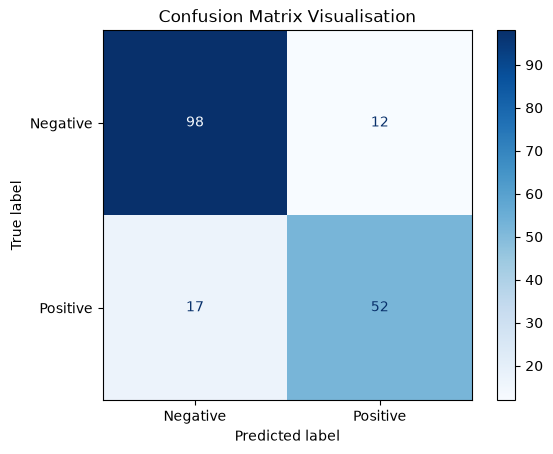

In [90]:
# Confusion Matrix for XGBoost model
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_val, y_pred)
print("Raw Confusion Matrix Matrix:\n", cm)

# 3. Extract individual components if needed
tn, fp, fn, tp = cm.ravel()
print(f"\nTN: {tn}, FP: {fp}, FN: {fn}, TP: {tp}")

# 4. Plot the Matrix visually
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Negative', 'Positive'])
disp.plot(cmap=plt.cm.Blues)

# 5. Show the plot
plt.title("Confusion Matrix Visualisation")
plt.show()